# SBC Fuzzy para decisões de economia no TFT

**Aluno:** Diego de Carvalho Dias — **Matrícula:** 20230089696

Este notebook implementa o sistema descrito no README. São duas perguntas, respondidas em ordem:

1. **Devo subir de nível?** Na maior parte do jogo, o calendário da curva padrão decide (regra crisp). Em **4-1**, a dúvida entre subir para o 8 agora ou em 4-2 é decidida por um controlador fuzzy com `ouro_apos_subir` e `hp`.
2. **Quanto do ouro que sobrou devo gastar roletando?** Controlador fuzzy com `pecas_faltando` e `hp`. Só se roleta a partir de 4-1 e no nível 8 ou mais.

Execute as células em ordem no Google Colab.

## 1. Instalação

In [ ]:
%pip -q install scikit-fuzzy

In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

print("scikit-fuzzy", fuzz.__version__)

scikit-fuzzy 0.5.0


## 2. Dados do jogo

Valores aproximados, que mudam um pouco entre sets. Se o jogo mudar, basta trocar estas constantes.

In [3]:
# XP necessário para ir do nível n ao n + 1.
XP_PARA_SUBIR = {1: 2, 2: 2, 3: 6, 4: 10, 5: 20, 6: 36, 7: 48, 8: 76, 9: 84}

# Curva padrão de nível (Set 17): rodada em que cada nível costuma ser atingido.
CURVA_NIVEL = [("2-1", 4), ("2-5", 5), ("3-2", 6), ("3-5", 7), ("4-2", 8), ("5-2", 9)]

OURO_POR_COMPRA_XP = 4   # cada compra dá 4 de XP
CUSTO_ROLAGEM = 2
PRIMEIRA_RODADA_DE_ROLAGEM = "4-1"
NIVEL_MINIMO_PARA_ROLETAR = 8

# A única dúvida de nível decidida pelo fuzzy: subir para o 8 em 4-1 ou esperar 4-2.
RODADA_DECISAO_FUZZY = "4-1"
NIVEL_DECISAO_FUZZY = 7

# Cortes crisp aplicados à saída defuzzificada.
CORTE_SUBIR = 50          # subir_nivel >= 50 -> compra o XP que falta
ZONA_NAO_ROLETAR = 25       # fracao_roletar < 25 % -> não roleta
ZONA_ALL_IN = 75          # fracao_roletar > 75 % -> gasta tudo


def eixo_estagio(estagio):
    """Converte "4-2" em um número contínuo: estágio + (rodada - 1) / 7."""
    try:
        e, r = (int(parte) for parte in estagio.split("-"))
    except ValueError:
        raise ValueError(f"estagio={estagio!r} inválido; use o formato do jogo, como '4-2'")
    if not (2 <= e <= 7 and 1 <= r <= 7):
        raise ValueError(f"estagio={estagio!r} fora do intervalo 2-1 a 7-7")
    return e + (r - 1) / 7


def ponto_da_curva(nivel_alvo):
    """Rodada em que a curva padrão pede o nível alvo (níveis até 4 já em 2-1)."""
    pontos = dict((nivel, rodada) for rodada, nivel in CURVA_NIVEL)
    if nivel_alvo <= CURVA_NIVEL[0][1]:
        return CURVA_NIVEL[0][0]
    return pontos.get(nivel_alvo)


def custo_para_subir(nivel, xp):
    if nivel not in XP_PARA_SUBIR:
        return None  # nível máximo
    xp_faltando = XP_PARA_SUBIR[nivel] - xp
    return OURO_POR_COMPRA_XP * math.ceil(xp_faltando / 4)


print("Ponto da curva do nível 8:", ponto_da_curva(8))
print("Custo para subir do 7 com 8/48 de XP:", custo_para_subir(7, 8))

Ponto da curva do nível 8: 4-2
Custo para subir do 7 com 8/48 de XP: 40


## 3. Variáveis linguísticas

Cada variável tem três termos, com as mesmas funções de pertinência mostradas no README.

/private/tmp/claude-501/-Users-diegodias-Programming-university-sistemas-baseados-em-conhecimento/6c340479-6f91-49b7-8222-eac2918fd78f/scratchpad/venv/lib/python3.14/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


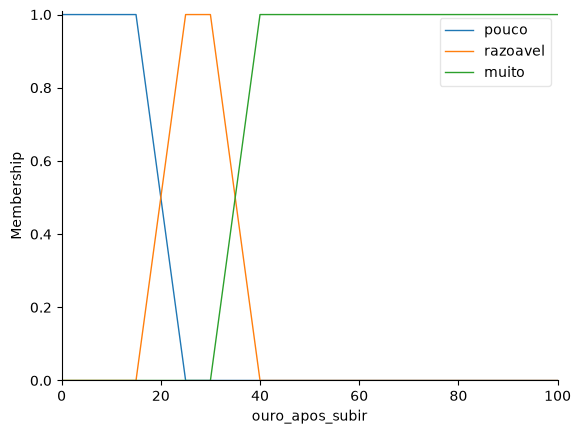

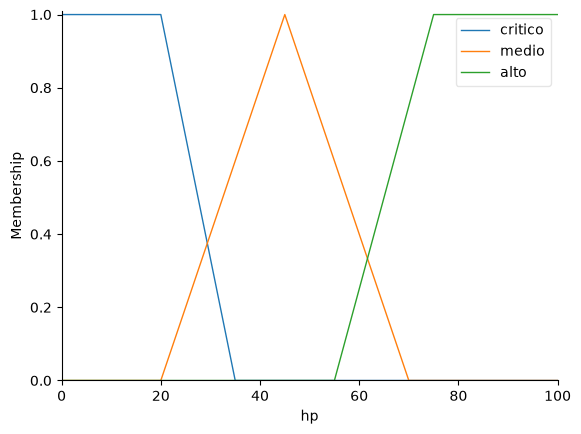

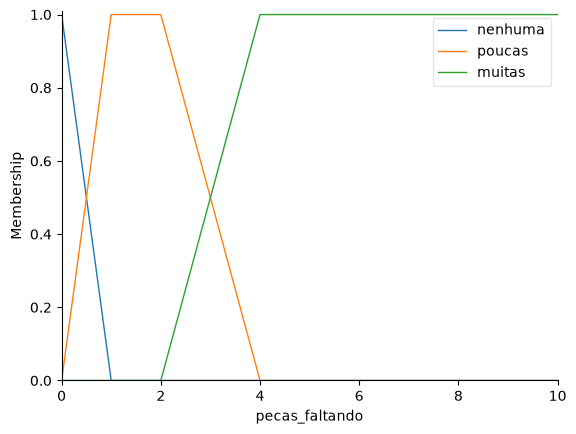

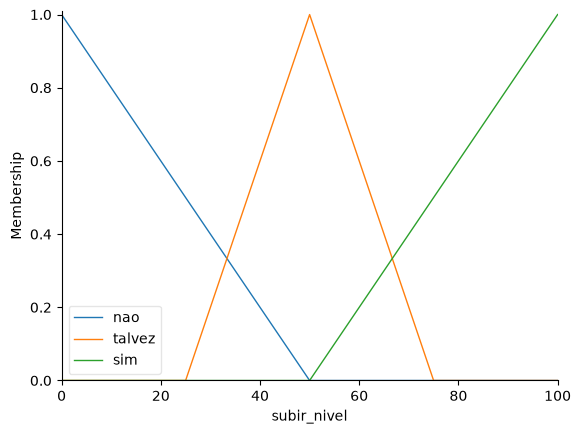

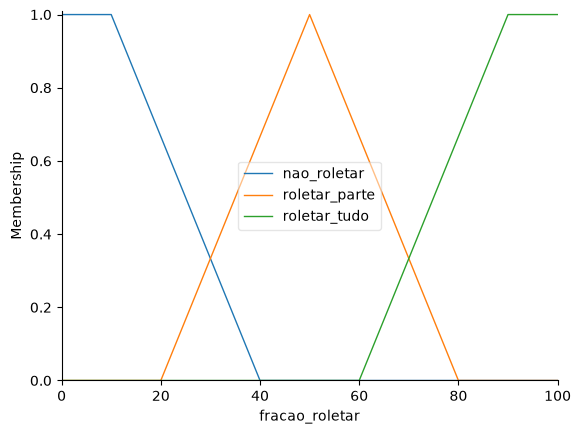

In [4]:
# Fronteiras do jogador: abaixo de 20 é pouco, de 20 a 34 é razoável, 35 ou mais é muito.
# Cada fronteira é o ponto em que dois termos valem 0,5.
var_ouro = ctrl.Antecedent(np.linspace(0, 100, 1001), "ouro_apos_subir")
var_ouro["pouco"] = fuzz.trapmf(var_ouro.universe, [0, 0, 15, 25])
var_ouro["razoavel"] = fuzz.trapmf(var_ouro.universe, [15, 25, 30, 40])
var_ouro["muito"] = fuzz.trapmf(var_ouro.universe, [30, 40, 100, 100])

var_hp = ctrl.Antecedent(np.linspace(0, 100, 201), "hp")
var_hp["critico"] = fuzz.trapmf(var_hp.universe, [0, 0, 20, 35])
var_hp["medio"] = fuzz.trimf(var_hp.universe, [20, 45, 70])
var_hp["alto"] = fuzz.trapmf(var_hp.universe, [55, 75, 100, 100])

var_pecas = ctrl.Antecedent(np.linspace(0, 10, 201), "pecas_faltando")
var_pecas["nenhuma"] = fuzz.trapmf(var_pecas.universe, [0, 0, 0, 1])
var_pecas["poucas"] = fuzz.trapmf(var_pecas.universe, [0, 1, 2, 4])
var_pecas["muitas"] = fuzz.trapmf(var_pecas.universe, [2, 4, 10, 10])

var_subir = ctrl.Consequent(np.linspace(0, 100, 1001), "subir_nivel")
var_subir["nao"] = fuzz.trimf(var_subir.universe, [0, 0, 50])
var_subir["talvez"] = fuzz.trimf(var_subir.universe, [25, 50, 75])
var_subir["sim"] = fuzz.trimf(var_subir.universe, [50, 100, 100])

var_fracao = ctrl.Consequent(np.linspace(0, 100, 1001), "fracao_roletar")
var_fracao["nao_roletar"] = fuzz.trapmf(var_fracao.universe, [0, 0, 10, 40])
var_fracao["roletar_parte"] = fuzz.trimf(var_fracao.universe, [20, 50, 80])
var_fracao["roletar_tudo"] = fuzz.trapmf(var_fracao.universe, [60, 90, 100, 100])

for variavel in (var_ouro, var_hp, var_pecas, var_subir, var_fracao):
    variavel.view()
plt.show()

## 4. Regras

Cada regra tem um ID, como no MP1, para aparecer na explicação. `N` são as regras de nível e `L` as de loja.

In [5]:
REGRAS_NIVEL = [
    # (id, ouro_apos_subir, hp, subir_nivel) — usadas só em 4-1, no nível 7
    ("N1", "pouco", "critico", "sim"),
    ("N2", "pouco", "medio", "nao"),
    ("N3", "pouco", "alto", "nao"),
    ("N4", "razoavel", "critico", "sim"),
    ("N5", "razoavel", "medio", "talvez"),
    ("N6", "razoavel", "alto", "talvez"),
    ("N7", "muito", "critico", "sim"),
    ("N8", "muito", "medio", "sim"),
    ("N9", "muito", "alto", "sim"),
]

REGRAS_LOJA = [
    # (id, pecas_faltando, hp, fracao_roletar)
    ("L1", "nenhuma", "critico", "nao_roletar"),
    ("L2", "nenhuma", "medio", "nao_roletar"),
    ("L3", "nenhuma", "alto", "nao_roletar"),
    ("L4", "poucas", "critico", "roletar_tudo"),
    ("L5", "poucas", "medio", "roletar_parte"),
    ("L6", "poucas", "alto", "nao_roletar"),
    ("L7", "muitas", "critico", "roletar_tudo"),
    ("L8", "muitas", "medio", "roletar_tudo"),
    ("L9", "muitas", "alto", "roletar_parte"),
]

sistema_nivel = ctrl.ControlSystem([
    ctrl.Rule(var_ouro[o] & var_hp[h], var_subir[s], label=rid)
    for rid, o, h, s in REGRAS_NIVEL
])
sistema_loja = ctrl.ControlSystem([
    ctrl.Rule(var_pecas[p] & var_hp[h], var_fracao[f], label=rid)
    for rid, p, h, f in REGRAS_LOJA
])

print(len(REGRAS_NIVEL) + len(REGRAS_LOJA), "regras fuzzy carregadas.")

18 regras fuzzy carregadas.


## 5. Motor de recomendação

`recomendar` recebe os números da tela do jogo e devolve a ação, os valores defuzzificados e as regras que dispararam com seu grau α.

Regras crisp:

| ID | Regra |
| --- | --- |
| C1 | Sem ouro para pagar o XP → não sobe |
| C2 | Chegou ao ponto da curva do próximo nível, ou passou dele → sobe |
| C3 | Em 4-1, no nível 7 → o Fuzzy 1 decide (`subir_nivel` ≥ 50 → sobe) |
| C4 | Qualquer outra situação → não sobe |
| C5 | Só roleta a partir de 4-1 e no nível 8 ou mais |
| C6 | Rolagens = fração × ouro restante ÷ 2; abaixo de 25 % não roleta, acima de 75 % gasta tudo |

O α é calculado como na Aula 3: o **E** usa o mínimo dos graus de pertinência. A defuzzificação (centroide) é feita pelo `scikit-fuzzy`.

In [6]:
def graus(variavel, valor):
    """Fuzzificação: grau de pertinência do valor em cada termo."""
    return {termo: float(fuzz.interp_membership(variavel.universe, mf.mf, valor))
            for termo, mf in variavel.terms.items()}


def regras_ativas(regras, graus_1, graus_2):
    """Avaliação: α = min(graus dos antecedentes), só das regras com α > 0."""
    ativas = []
    for rid, t1, t2, saida in regras:
        alfa = min(graus_1[t1], graus_2[t2])
        if alfa > 0:
            ativas.append((rid, t1, t2, saida, round(alfa, 2)))
    return ativas


def validar(estagio, nivel, xp, ouro, hp_atual, pecas):
    eixo_estagio(estagio)
    if not 1 <= nivel <= 10:
        raise ValueError(f"nivel={nivel} inválido; use de 1 a 10")
    if nivel in XP_PARA_SUBIR and not 0 <= xp < XP_PARA_SUBIR[nivel]:
        raise ValueError(f"xp={xp} inválido para o nível {nivel}; use de 0 a {XP_PARA_SUBIR[nivel] - 1}")
    if ouro < 0:
        raise ValueError("ouro não pode ser negativo")
    if not 0 <= hp_atual <= 100:
        raise ValueError(f"hp={hp_atual} inválido; use de 0 a 100")
    if not 0 <= pecas <= nivel:
        raise ValueError(f"pecas_faltando={pecas} inválido; use de 0 até o nível ({nivel})")


def recomendar(estagio, nivel, xp, ouro, hp, pecas_faltando):
    hp_atual, pecas = hp, pecas_faltando
    validar(estagio, nivel, xp, ouro, hp_atual, pecas)
    r = {"entrada": dict(estagio=estagio, nivel=nivel, xp=xp, ouro=ouro, hp=hp_atual, pecas_faltando=pecas)}
    g_hp = graus(var_hp, hp_atual)

    # Pergunta 1: subir de nível?
    custo = custo_para_subir(nivel, xp)
    ponto = ponto_da_curva(nivel + 1)
    r["custo_subir"] = custo
    r["subir_nivel"] = None
    r["regras_nivel"] = []
    r["sobe"] = False
    if custo is None:
        r["motivo_nivel"] = "C1: já está no nível máximo"
    elif custo > ouro:
        r["motivo_nivel"] = f"C1: subir custa {custo} e só há {ouro} de ouro"
    elif ponto and eixo_estagio(estagio) >= eixo_estagio(ponto):
        r["sobe"] = True
        r["motivo_nivel"] = f"C2: o nível {nivel + 1} é esperado a partir de {ponto}"
    elif estagio == RODADA_DECISAO_FUZZY and nivel == NIVEL_DECISAO_FUZZY:
        sobra = min(ouro - custo, 100)
        sim = ctrl.ControlSystemSimulation(sistema_nivel)
        sim.input["ouro_apos_subir"] = sobra
        sim.input["hp"] = hp_atual
        sim.compute()
        r["subir_nivel"] = round(float(sim.output["subir_nivel"]), 1)
        r["regras_nivel"] = regras_ativas(REGRAS_NIVEL, graus(var_ouro, sobra), g_hp)
        r["sobe"] = r["subir_nivel"] >= CORTE_SUBIR
        r["motivo_nivel"] = (f"C3: sobram {ouro - custo} depois de subir · subir_nivel = {r['subir_nivel']} "
                             f"{'>=' if r['sobe'] else '<'} {CORTE_SUBIR}")
        r["_sim_nivel"] = sim
    else:
        quando = f"só em {ponto}" if ponto else "fora da curva"
        r["motivo_nivel"] = f"C4: o nível {nivel + 1} é esperado {quando}"

    ouro_restante = ouro - (custo if r["sobe"] else 0)
    r["ouro_restante"] = ouro_restante

    # Pergunta 2: quanto roletar?
    r["fracao_roletar"] = None
    r["regras_loja"] = []
    nivel_final = nivel + (1 if r["sobe"] else 0)
    if eixo_estagio(estagio) < eixo_estagio(PRIMEIRA_RODADA_DE_ROLAGEM):
        r["motivo_loja"] = f"C5: antes de {PRIMEIRA_RODADA_DE_ROLAGEM} não se roleta"
        fracao_efetiva = 0.0
    elif nivel_final < NIVEL_MINIMO_PARA_ROLETAR:
        r["motivo_loja"] = f"C5: no nível {nivel_final} não se roleta; espera chegar ao {NIVEL_MINIMO_PARA_ROLETAR}"
        fracao_efetiva = 0.0
    else:
        sim = ctrl.ControlSystemSimulation(sistema_loja)
        sim.input["pecas_faltando"] = pecas
        sim.input["hp"] = hp_atual
        sim.compute()
        fracao = round(float(sim.output["fracao_roletar"]), 1)
        r["fracao_roletar"] = fracao
        r["regras_loja"] = regras_ativas(REGRAS_LOJA, graus(var_pecas, pecas), g_hp)
        r["_sim_loja"] = sim
        if fracao < ZONA_NAO_ROLETAR:
            fracao_efetiva, zona = 0.0, f"abaixo de {ZONA_NAO_ROLETAR} % → não roleta"
        elif fracao > ZONA_ALL_IN:
            fracao_efetiva, zona = 1.0, f"acima de {ZONA_ALL_IN} % → gasta tudo"
        else:
            fracao_efetiva, zona = fracao / 100, "usa a fração"
        r["motivo_loja"] = f"C6: fracao_roletar = {fracao} % ({zona})"

    r["rolagens"] = int(fracao_efetiva * ouro_restante) // CUSTO_ROLAGEM
    r["guarda"] = ouro_restante - r["rolagens"] * CUSTO_ROLAGEM
    r["acao"] = texto_da_acao(r, nivel)
    return r


def texto_da_acao(r, nivel):
    partes = []
    if r["sobe"]:
        partes.append(f"suba para o nível {nivel + 1} ({r['custo_subir']} de ouro)")
    else:
        partes.append("não suba de nível")
    if r["rolagens"]:
        partes.append(f"rolete {r['rolagens']}× ({r['rolagens'] * CUSTO_ROLAGEM} de ouro)")
    else:
        partes.append("não rolete")
    frase = ", ".join(partes)
    return f"{frase[0].upper()}{frase[1:]}, guardando {r['guarda']} de ouro."


def mostrar(nome, r, graficos=False):
    e = r["entrada"]
    print(f"\n{nome}")
    print(f"Entrada: {e['estagio']}, nível {e['nivel']} ({e['xp']} XP), {e['ouro']} de ouro, "
          f"HP {e['hp']}, faltam {e['pecas_faltando']} peças")
    print(f"Nível   → {r['motivo_nivel']}")
    for rid, o, h, s, alfa in r["regras_nivel"]:
        print(f"          {rid}: ouro {o} E hp {h} → {s}  (α = {alfa})")
    print(f"Loja    → {r['motivo_loja']}")
    for rid, p, h, f, alfa in r["regras_loja"]:
        print(f"          {rid}: peças {p} E hp {h} → {f}  (α = {alfa})")
    print(f"Ação    → {r['acao']}")
    if graficos:
        if "_sim_nivel" in r:
            var_subir.view(sim=r["_sim_nivel"])
        if "_sim_loja" in r:
            var_fracao.view(sim=r["_sim_loja"])
        plt.show()

## 6. Casos de teste obrigatórios

Cada caso mostra a entrada, as regras que dispararam, a saída defuzzificada e a interpretação.


Caso 1 — Subir em 4-1 ou esperar 4-2?
Entrada: 4-1, nível 7 (8 XP), 60 de ouro, HP 60, faltam 3 peças
Nível   → C3: sobram 20 depois de subir · subir_nivel = 35.1 < 50
          N2: ouro pouco E hp medio → nao  (α = 0.4)
          N3: ouro pouco E hp alto → nao  (α = 0.25)
          N5: ouro razoavel E hp medio → talvez  (α = 0.4)
          N6: ouro razoavel E hp alto → talvez  (α = 0.25)
Loja    → C5: no nível 7 não se roleta; espera chegar ao 8
Ação    → Não suba de nível, não rolete, guardando 60 de ouro.


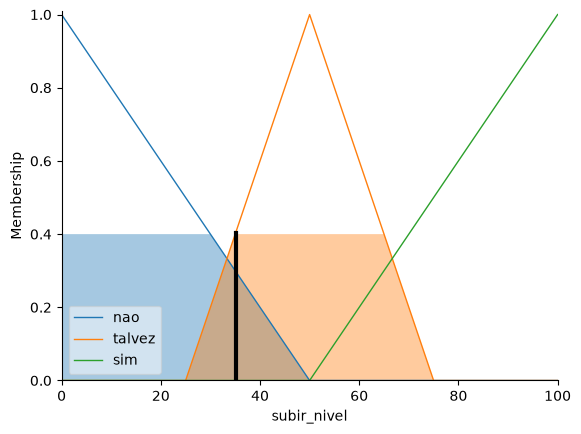

In [7]:
# Caso 1 — Subir em 4-1 ou esperar 4-2?
# Entrada: 4-1, nível 7 com 8/48 de XP, 60 de ouro, HP 60, faltam 3 peças.
caso1 = recomendar(estagio="4-1", nivel=7, xp=8, ouro=60, hp=60, pecas_faltando=3)
mostrar("Caso 1 — Subir em 4-1 ou esperar 4-2?", caso1, graficos=True)

# Saída esperada: subir_nivel ≈ 35 → espera 4-2, e não roleta.
# Interpretação: subir custa 40 e sobrariam só 20 de ouro, metade "pouco" e metade "razoável".
# Com HP confortável, as regras "pouco → não" e "razoável → talvez" se misturam e o resultado
# fica abaixo de 50: melhor esperar 4-2 e chegar lá com mais ouro para o roll-down.
# Como continua no nível 7, a regra C5 impede roletar.
assert not caso1["sobe"] and 25 < caso1["subir_nivel"] < 50
assert caso1["rolagens"] == 0 and caso1["guarda"] == 60


Caso 2 — Roll-down em 4-2
Entrada: 4-2, nível 7 (8 XP), 70 de ouro, HP 60, faltam 3 peças
Nível   → C2: o nível 8 é esperado a partir de 4-2
Loja    → C6: fracao_roletar = 54.3 % (usa a fração)
          L5: peças poucas E hp medio → roletar_parte  (α = 0.4)
          L6: peças poucas E hp alto → nao_roletar  (α = 0.25)
          L8: peças muitas E hp medio → roletar_tudo  (α = 0.4)
          L9: peças muitas E hp alto → roletar_parte  (α = 0.25)
Ação    → Suba para o nível 8 (40 de ouro), rolete 8× (16 de ouro), guardando 14 de ouro.


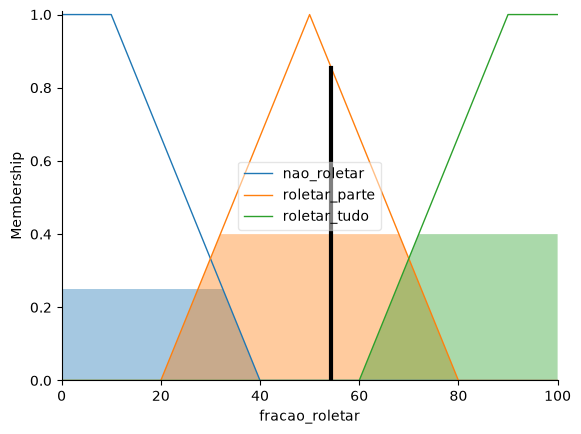

In [8]:
# Caso 2 — Roll-down em 4-2
# Entrada: 4-2, nível 7 com 8/48 de XP, 70 de ouro, HP 60, faltam 3 peças.
caso2 = recomendar(estagio="4-2", nivel=7, xp=8, ouro=70, hp=60, pecas_faltando=3)
mostrar("Caso 2 — Roll-down em 4-2", caso2, graficos=True)

# Saída esperada: sobe para o 8 (C2) e fracao_roletar ≈ 54 %.
# Interpretação: 4-2 é o ponto da curva do nível 8, então sobe pelo calendário. Na loja,
# 3 peças são meio "poucas" e meio "muitas", e o HP 60 está entre médio e alto: quatro
# regras votam e o resultado é uma rolagem moderada, sem ir all-in.
assert caso2["sobe"] and caso2["subir_nivel"] is None
assert 45 < caso2["fracao_roletar"] < 60 and caso2["rolagens"] == 8


Caso 3 — HP crítico em 4-1
Entrada: 4-1, nível 7 (8 XP), 44 de ouro, HP 18, faltam 2 peças
Nível   → C3: sobram 4 depois de subir · subir_nivel = 83.3 >= 50
          N1: ouro pouco E hp critico → sim  (α = 1.0)
Loja    → C6: fracao_roletar = 86.0 % (acima de 75 % → gasta tudo)
          L4: peças poucas E hp critico → roletar_tudo  (α = 1.0)
Ação    → Suba para o nível 8 (40 de ouro), rolete 2× (4 de ouro), guardando 0 de ouro.


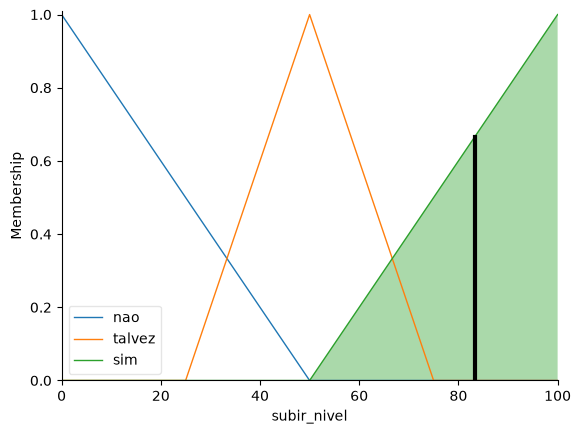

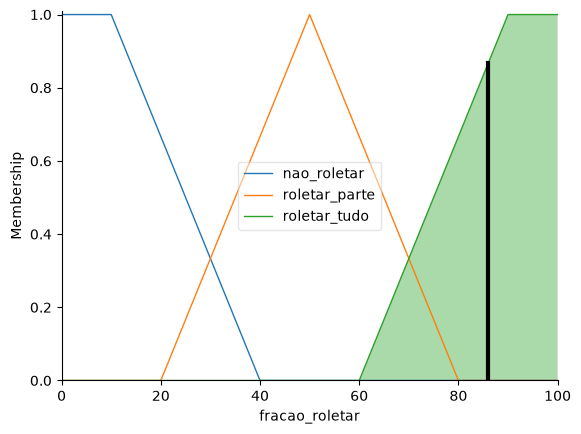

In [9]:
# Caso 3 — HP crítico em 4-1
# Entrada: 4-1, nível 7 com 8/48 de XP, 44 de ouro, HP 18, faltam 2 peças.
caso3 = recomendar(estagio="4-1", nivel=7, xp=8, ouro=44, hp=18, pecas_faltando=2)
mostrar("Caso 3 — HP crítico em 4-1", caso3, graficos=True)

# Saída esperada: subir_nivel ≈ 83 → sobe, e fracao_roletar ≈ 86 % (all-in).
# Interpretação: mesmo sobrando só 4 de ouro, com HP crítico a regra "pouco + crítico → sim"
# manda subir uma rodada antes, porque o jogador precisa do tabuleiro mais forte agora.
# Já no 8, o pouco que sobrou vai todo para a loja (equivale a R15 do MP1).
assert caso3["sobe"] and caso3["subir_nivel"] > 75
assert caso3["fracao_roletar"] > ZONA_ALL_IN and caso3["guarda"] == 0

## 7. Casos extras

In [10]:
# Caso 4 — 4-1 com muito ouro: sobram 40 depois de subir, então sobe uma rodada antes e roleta.
caso4 = recomendar(estagio="4-1", nivel=7, xp=8, ouro=80, hp=80, pecas_faltando=4)
mostrar("Caso 4 — 4-1 com muito ouro", caso4)
assert caso4["sobe"] and caso4["rolagens"] > 0

# Caso 5 — Economia no estágio 3: o nível 7 só é esperado em 3-5 e não se roleta antes de 4-1.
caso5 = recomendar(estagio="3-3", nivel=6, xp=10, ouro=42, hp=80, pecas_faltando=4)
mostrar("Caso 5 — Economia no estágio 3", caso5)
assert not caso5["sobe"] and caso5["rolagens"] == 0 and caso5["guarda"] == 42

# Caso 6 — Composição pronta: o nível 9 só vem em 5-2 e não há o que buscar na loja.
caso6 = recomendar(estagio="4-5", nivel=8, xp=10, ouro=58, hp=85, pecas_faltando=0)
mostrar("Caso 6 — Composição pronta", caso6)
assert not caso6["sobe"] and caso6["rolagens"] == 0

# Caso 7 — Sem ouro para o 8 em 4-3: não sobe (C1) e também não roleta no 7 (C5).
# Roletar no 7 a partir do estágio 4 desperdiça ouro; o certo é juntar para subir.
caso7 = recomendar(estagio="4-3", nivel=7, xp=0, ouro=30, hp=55, pecas_faltando=4)
mostrar("Caso 7 — Sem ouro para o 8", caso7)
assert not caso7["sobe"] and caso7["rolagens"] == 0 and caso7["guarda"] == 30


Caso 4 — 4-1 com muito ouro
Entrada: 4-1, nível 7 (8 XP), 80 de ouro, HP 80, faltam 4 peças
Nível   → C3: sobram 40 depois de subir · subir_nivel = 83.3 >= 50
          N9: ouro muito E hp alto → sim  (α = 1.0)
Loja    → C6: fracao_roletar = 50.0 % (usa a fração)
          L9: peças muitas E hp alto → roletar_parte  (α = 1.0)
Ação    → Suba para o nível 8 (40 de ouro), rolete 10× (20 de ouro), guardando 20 de ouro.

Caso 5 — Economia no estágio 3
Entrada: 3-3, nível 6 (10 XP), 42 de ouro, HP 80, faltam 4 peças
Nível   → C4: o nível 7 é esperado só em 3-5
Loja    → C5: antes de 4-1 não se roleta
Ação    → Não suba de nível, não rolete, guardando 42 de ouro.

Caso 6 — Composição pronta
Entrada: 4-5, nível 8 (10 XP), 58 de ouro, HP 85, faltam 0 peças
Nível   → C1: subir custa 68 e só há 58 de ouro
Loja    → C6: fracao_roletar = 14.0 % (abaixo de 25 % → não roleta)
          L3: peças nenhuma E hp alto → nao_roletar  (α = 1.0)
Ação    → Não suba de nível, não rolete, guardando 58 de ouro.

## 8. Pontos da curva de nível

Nas rodadas em que a curva padrão pede um novo nível (2-1, 2-5, 3-2, 3-5, 4-2 e 5-2), o sistema deve:

- **subir** se o jogador está um nível abaixo, com a barra de XP vazia ou quase cheia;
- **não subir** se o jogador já está no nível esperado;
- **não subir** na rodada anterior, com uma exceção: em **4-1**, o Fuzzy 1 decide pelo ouro e pelo HP.

In [11]:
def rodada_anterior(rodada):
    e, r = (int(p) for p in rodada.split("-"))
    return f"{e}-{r - 1}" if r > 1 else f"{e - 1}-7"


print(f"{'Ponto':6} {'Nível':>5} | {'barra vazia':>11} | {'barra quase cheia':>17} | {'já no nível':>11} | rodada anterior")
for rodada, alvo in CURVA_NIVEL:
    abaixo = alvo - 1
    quase_cheia = XP_PARA_SUBIR[abaixo] - 2
    vazia = recomendar(rodada, abaixo, 0, 100, 60, 2)
    cheia = recomendar(rodada, abaixo, quase_cheia, 100, 60, 2)
    no_nivel = recomendar(rodada, alvo, 0, 100, 60, 2)
    assert vazia["sobe"] and cheia["sobe"] and not no_nivel["sobe"], rodada

    if rodada == "2-1":
        txt_antes = "—"
    else:
        anterior = rodada_anterior(rodada)
        antes = recomendar(anterior, abaixo, 0, 100, 60, 2)
        if anterior == RODADA_DECISAO_FUZZY:
            txt_antes = f"{anterior}: fuzzy, sobram {100 - antes['custo_subir']} → {'sobe' if antes['sobe'] else 'espera'}"
        else:
            assert not antes["sobe"], rodada
            txt_antes = f"{anterior}: espera"
    print(f"{rodada:6} {alvo:>5} | {'sobe':>11} | {'sobe (' + str(quase_cheia) + '/' + str(XP_PARA_SUBIR[abaixo]) + ')':>17} | "
          f"{'não':>11} | {txt_antes}")

print("\nTodos os pontos da curva se comportaram como esperado.")

Ponto  Nível | barra vazia | barra quase cheia | já no nível | rodada anterior
2-1        4 |        sobe |        sobe (4/6) |         não | —
2-5        5 |        sobe |       sobe (8/10) |         não | 2-4: espera
3-2        6 |        sobe |      sobe (18/20) |         não | 3-1: espera
3-5        7 |        sobe |      sobe (34/36) |         não | 3-4: espera
4-2        8 |        sobe |      sobe (46/48) |         não | 4-1: fuzzy, sobram 52 → sobe
5-2        9 |        sobe |      sobe (74/76) |         não | 5-1: espera

Todos os pontos da curva se comportaram como esperado.


## 9. Saída suave

No MP1, HP era `baixo` ou `alto`, e a decisão mudava de uma vez. Aqui, variando só o HP, o ouro gasto na loja diminui aos poucos. O segundo gráfico mostra a decisão de 4-1: quanto mais ouro sobra depois de subir, mais forte a recomendação, e com HP crítico ela já começa alta.

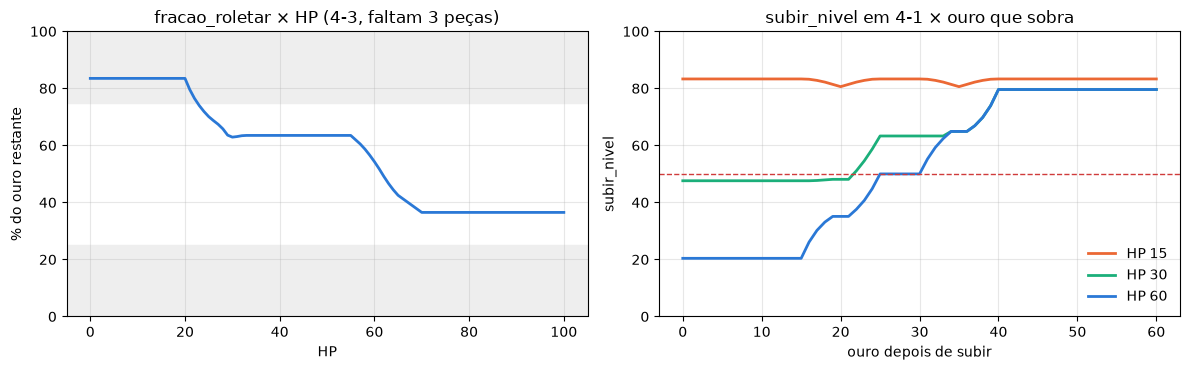

HP  :   20   30   40   50   60   70   80
%   :   84   63   64   64   54   36   36


In [12]:
hps = np.arange(0, 101, 1)
fracoes = [recomendar("4-3", 8, 0, 60, int(h), 3)["fracao_roletar"] for h in hps]

sobras = np.arange(0, 61, 1)
curvas_hp = {hp_ex: [recomendar("4-1", 7, 8, 40 + int(sb), hp_ex, 3)["subir_nivel"] for sb in sobras]
             for hp_ex in (15, 30, 60)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(hps, fracoes, lw=2, color="#2a78d6")
ax1.axhspan(0, ZONA_NAO_ROLETAR, color="#eeeeee", zorder=0)
ax1.axhspan(ZONA_ALL_IN, 100, color="#eeeeee", zorder=0)
ax1.set(title="fracao_roletar × HP (4-3, faltam 3 peças)", xlabel="HP", ylabel="% do ouro restante", ylim=(0, 100))

for (hp_ex, ys), cor in zip(curvas_hp.items(), ("#eb6834", "#1baf7a", "#2a78d6")):
    ax2.plot(sobras, ys, lw=2, color=cor, label=f"HP {hp_ex}")
ax2.axhline(CORTE_SUBIR, color="#d03b3b", ls="--", lw=1)
ax2.legend(frameon=False)
ax2.set(title="subir_nivel em 4-1 × ouro que sobra", xlabel="ouro depois de subir", ylabel="subir_nivel", ylim=(0, 100))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("HP  :", *[f"{h:>4}" for h in range(20, 81, 10)])
print("%   :", *[f"{fracoes[h]:>4.0f}" for h in range(20, 81, 10)])

## 10. Comparação com o MP1

Os casos do MP1 que usam a estratégia padrão no estágio 4+, traduzidos para números. "HP baixo" virou 25, "alto" virou 80; "ouro baixo" virou 20, "alto" virou 60.

In [13]:
casos_mp1 = [
    ("MP1 caso 1: peças faltando, HP baixo, ouro baixo", "roletar",     dict(hp=25, ouro=20)),
    ("MP1 caso 3: peças faltando, HP alto, ouro baixo",  "salvar_ouro", dict(hp=80, ouro=20)),
    ("MP1 caso 6: peças faltando, HP alto, ouro alto",   "roletar",     dict(hp=80, ouro=60)),
]
print(f"{'Caso':52} {'MP1':12} MP2")
for nome, decisao_mp1, v in casos_mp1:
    r = recomendar(estagio="4-3", nivel=8, xp=0, pecas_faltando=3, **v)
    print(f"{nome:52} {decisao_mp1:12} {r['acao']}")

Caso                                                 MP1          MP2
MP1 caso 1: peças faltando, HP baixo, ouro baixo     roletar      Não suba de nível, rolete 7× (14 de ouro), guardando 6 de ouro.
MP1 caso 3: peças faltando, HP alto, ouro baixo      salvar_ouro  Não suba de nível, rolete 3× (6 de ouro), guardando 14 de ouro.
MP1 caso 6: peças faltando, HP alto, ouro alto       roletar      Não suba de nível, rolete 10× (20 de ouro), guardando 40 de ouro.


Os casos 1 e 6 dão a mesma direção nos dois sistemas, mas o MP2 diz **quanto** roletar. O caso 3 é diferente: o MP1 guardava o ouro por estar "baixo", e o MP2 roleta parte dele, porque o modelo ignora juros (premissa do README). Esse é um bom exemplo de como as premissas mudam o comportamento.

## 11. Verificação de lacunas

Percorre uma grade de entradas e confirma que, em todo ponto, pelo menos uma regra de cada controlador dispara (α > 0). Se alguma combinação ficasse sem regra, o `scikit-fuzzy` não conseguiria calcular a saída.

In [14]:
lacunas = []
for o in range(0, 101):
    g_o = graus(var_ouro, o)
    for h in range(0, 101):
        if not regras_ativas(REGRAS_NIVEL, g_o, graus(var_hp, h)):
            lacunas.append(("nível", o, h))
for p in np.round(np.arange(0, 10.001, 0.25), 2):
    g_p = graus(var_pecas, p)
    for h in range(0, 101):
        if not regras_ativas(REGRAS_LOJA, g_p, graus(var_hp, h)):
            lacunas.append(("loja", p, h))

assert not lacunas, lacunas[:10]
print("Nenhuma lacuna: toda combinação de entradas ativa pelo menos uma regra em cada controlador.")

for estagio_invalido in ("1-3", "4-9", "42"):
    try:
        recomendar(estagio_invalido, 7, 0, 50, 50, 2)
    except ValueError as erro:
        print("Rejeitado:", erro)

Nenhuma lacuna: toda combinação de entradas ativa pelo menos uma regra em cada controlador.
Rejeitado: estagio='1-3' fora do intervalo 2-1 a 7-7
Rejeitado: estagio='4-9' fora do intervalo 2-1 a 7-7
Rejeitado: estagio='42' inválido; use o formato do jogo, como '4-2'


## 12. Experimente

Troque os valores e execute a célula.

In [ ]:
minha_rodada = recomendar(
    estagio="4-2", 
    nivel=7, 
    xp=8, 
    ouro=70, 
    hp=60, 
    pecas_faltando=3
)
mostrar("Minha rodada", minha_rodada)


Minha rodada
Entrada: 4-2, nível 7 (8 XP), 70 de ouro, HP 60, faltam 3 peças
Nível   → C2: o nível 8 é esperado a partir de 4-2
Loja    → C6: fracao_roletar = 54.3 % (usa a fração)
          L5: peças poucas E hp medio → roletar_parte  (α = 0.4)
          L6: peças poucas E hp alto → nao_roletar  (α = 0.25)
          L8: peças muitas E hp medio → roletar_tudo  (α = 0.4)
          L9: peças muitas E hp alto → roletar_parte  (α = 0.25)
Ação    → Suba para o nível 8 (40 de ouro), rolete 8× (16 de ouro), guardando 14 de ouro.
